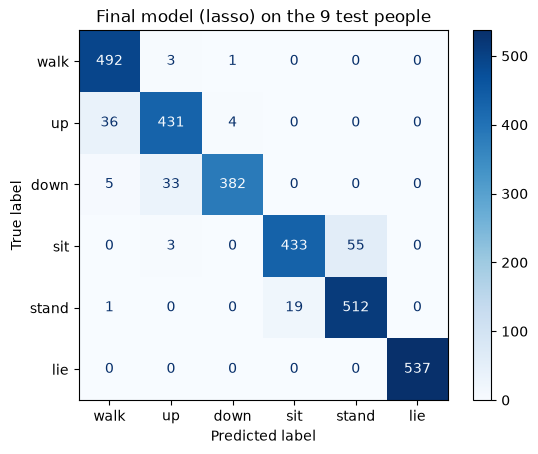

              precision    recall  f1-score   support

        walk      0.921     0.992     0.955       496
          up      0.917     0.915     0.916       471
        down      0.987     0.910     0.947       420
         sit      0.958     0.882     0.918       491
       stand      0.903     0.962     0.932       532
         lie      1.000     1.000     1.000       537

    accuracy                          0.946      2947
   macro avg      0.948     0.943     0.945      2947
weighted avg      0.947     0.946     0.946      2947



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from config import SEED, DATA

t = pd.read_csv("results/test_predictions_lasso.csv")
labels = ["walk", "up", "down", "sit", "stand", "lie"]

cm = confusion_matrix(t["true"], t["pred"], labels=[1, 2, 3, 4, 5, 6])
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Final model (lasso) on the 9 test people")
plt.show()

print(classification_report(t["true"], t["pred"], target_names=labels, digits=3))

In [2]:
names = dict(zip(range(1, 7), labels))
t["wrong"] = t["true"] != t["pred"]
t["pair"] = t["true"].map(names) + " → " + t["pred"].map(names)

errors = t[t["wrong"]]
table = pd.crosstab(errors["person"], errors["pair"])
table["total"] = table.sum(axis=1)
print(table.sort_values("total", ascending=False))

pair    down → up  down → walk  sit → stand  sit → up  stand → sit  \
person                                                               
10              0            0           19         0            4   
9               0            0           10         3           12   
20             21            0            6         0            0   
4               0            1            4         0            3   
18             12            0            2         0            0   
12              0            1            9         0            0   
2               0            0            5         0            0   
13              0            3            0         0            0   

pair    stand → walk  up → down  up → walk  walk → down  walk → up  total  
person                                                                     
10                 0          4         20            1          0     48  
9                  0          0          9            0          0     

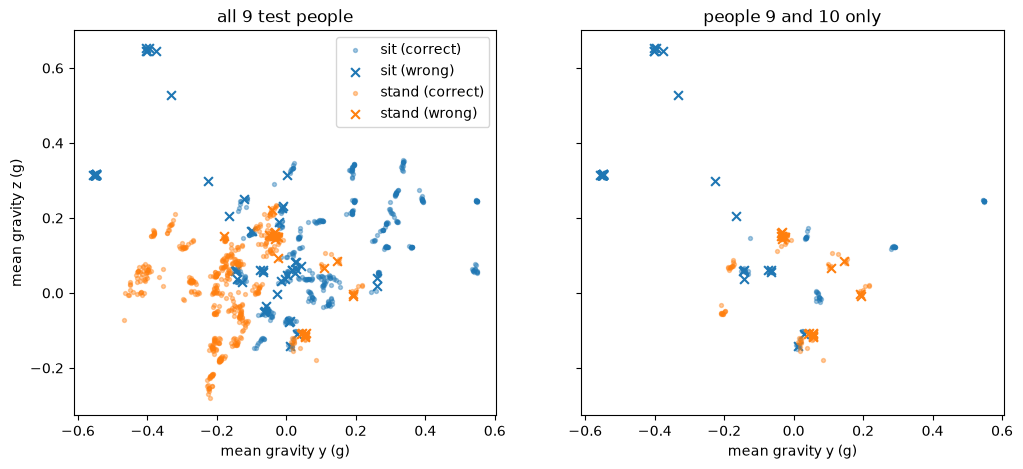

In [3]:
folder = DATA + "/test/Inertial Signals/"
for ax_name in ["x", "y", "z"]:
    t["g" + ax_name] = np.loadtxt(folder + "total_acc_" + ax_name + "_test.txt").mean(axis=1)

still = t[t["true"].isin([4, 5])]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, who in zip(axes, [None, [9, 10]]):
    d = still if who is None else still[still["person"].isin(who)]
    for lab, col in [(4, "tab:blue"), (5, "tab:orange")]:
        ok = d[(d["true"] == lab) & ~d["wrong"]]
        bad = d[(d["true"] == lab) & d["wrong"]]
        ax.scatter(ok["gy"], ok["gz"], s=8, alpha=0.4, color=col, label=names[lab] + " (correct)")
        ax.scatter(bad["gy"], bad["gz"], s=40, marker="x", color=col, label=names[lab] + " (wrong)")
    ax.set_xlabel("mean gravity y (g)")
    ax.set_title("all 9 test people" if who is None else "people 9 and 10 only")
axes[0].set_ylabel("mean gravity z (g)")
axes[0].legend()
plt.show()

In [4]:
prob_cols = ["p_walk", "p_up", "p_down", "p_sit", "p_stand", "p_lie"]
t["confidence"] = t[prob_cols].max(axis=1)
wrong = t[t["wrong"]]

print("wrong windows:", len(wrong), "  of which over 90% confident:", (wrong["confidence"] > 0.9).sum())
print(wrong[wrong["confidence"] > 0.9].groupby(["person", "pair"]).size())

for lo, hi in [(0, 0.6), (0.6, 0.9), (0.9, 1.01)]:
    band = (t["confidence"] >= lo) & (t["confidence"] < hi)
    print("confidence", lo, "to", min(hi, 1), ":", band.sum(), "windows, accuracy", round(1 - t.loc[band, "wrong"].mean(), 3))
    

wrong windows: 160   of which over 90% confident: 23
person  pair       
4       sit → stand     1
9       sit → stand     2
        sit → up        2
        stand → sit     1
10      sit → stand    12
        up → walk       2
20      down → up       3
dtype: int64
confidence 0 to 0.6 : 132 windows, accuracy 0.583
confidence 0.6 to 0.9 : 519 windows, accuracy 0.842
confidence 0.9 to 1 : 2296 windows, accuracy 0.99


# Part 8 summary: error analysis of the final model (lasso, C = 0.1) on the 9 test people

All results come from the saved test predictions (`results/test_predictions_lasso.csv`); nothing was refitted or chosen here.

## Which activities get confused (confusion matrix, 160 errors of 2,947 windows)
| Block | Errors | Main mistakes |
|---|---|---|
| Still postures | 74 | sit → stand 55, stand → sit 19 |
| Walking types | 82 | up → walk 36, down → up 33 |
| Moving ↔ still | 4 | essentially never |

- **Lying is perfect** (537/537): gravity direction changes completely.
- The model **never confuses moving with still**. All real errors are fine distinctions *within* the still block or *within* the walking block.
- Lowest recall: **sitting, 0.882**. Sit → stand is about 3× more common than stand → sit: ambiguous sitting postures are pulled towards "standing" (standing precision 0.903).

## Who the errors belong to
- **People 10, 9 and 20 make 113 of the 160 errors (71%)**; person 24 makes none.
- **Stairs errors are person-specific:** down → up comes only from person 20 (21) and person 18 (12); up → walk mostly from 10 (20), 9 (9) and 4 (7).
- **Sit → stand is general:** it appears in 7 of 9 people (worst: 10 with 19, 9 with 10, 12 with 9).
- Person 9 errs in both directions (sit → stand 10, stand → sit 12): their two postures look alike to the phone.

## Why (physics check: mean gravity y vs z for still windows)
- Standing sits mostly at negative gravity y, sitting at positive y, with an overlap in between. **Most sit/stand errors lie in that overlap**: the posture tilt is ambiguous.
- Some of person 9's and 10's sitting windows lie **outside every other person's cloud**: a posture not seen in training. The model labels these "standing", often confidently.
- **Errors come in clumps**: a whole bout of near-identical windows is wrong together (another reason to bootstrap over people, not windows).
- Caveat: this plot shows 2 of 561 features; it explains much of the confusion, not every error.

## Confidence
| Confidence | Windows | Accuracy |
|---|---|---|
| < 0.6 | 132 | 0.58 |
| 0.6–0.9 | 519 | 0.84 |
| ≥ 0.9 | 2,296 | 0.99 |

- Abstaining below 0.9 would leave 22% of windows unlabelled but catch about 86% of errors; the model would then be 99% right when it answers.
- **23 errors are over 90% confident**, 12 of them person 10's sit → stand bout. Confidence cannot flag postures unlike the training people's.

## Limitations
1. **Who it was trained on:** 21 adults, scripted activities in a lab, one phone model (Galaxy S II) at one position (waist). Other placements, phones, ages, or free-living behaviour are untested here (Part 10 tests our own recordings).
2. **Unfamiliar postures fail confidently.** The model only knows postures like its training people's; new ones are mislabelled with high confidence.
3. **Small number of people.** 9 test people give a wide 95% interval (0.906–0.975); per-person scores range from 0.83 to 1.00, so the average hides individuals with about 1 in 6 windows wrong.
4. **Errors are correlated** within bouts and people, so window counts overstate how much independent evidence we have.
5. **Each window is classified independently.** Activities last many windows; smoothing predictions over time could fix isolated errors, but was not tested.
6. **No transitions.** The dataset's six activities exclude transitions (e.g. sit-to-stand); real use would include them.
7. **Prediction, not explanation.** Lasso's kept features change between folds, and importance is shared among correlated features, so we make no claims about which features "cause" an activity to be recognised.